# PMIP4 past1000/hist continuity 

The PMIP `past1000` protocol, which runs from 850-1849 CE (or, in a few cases, to 1850), is distinct from the `historical` protocol, making connecting those simulations somewhat tricky unless the historical simulations used a restart file corresponding to the end of a `past2k/past1000` simulation. However, in some applications it is ncessary to extend `past1000` to the present day regardless of the initialization of the historical runs in 1850. This notebook investigates the 1850 discontinuity in 9 GCMs: ACCESS-ESM1-5, CESM1.1, CESM2, EC-Earth3-Veg-LR, INM-CM4-8, iCESM, MIROC-ES2L, MPI-ESM1-2-LR, MRI-ESM2-0.
Note that iCESM was run continuously from 850 to 2005 (see [Brady et al (2019)](https://doi.org/10.1029/2019MS001663)), and CESM1.1 ran the `past2k` protocol through the present — those 2 simulations do not require a hand stitch. MPI-ESM1-2-LR also ran `past2k` but the data in store ends at CE 1849 and is stitched with a CMIP6 historical run like the other `past1000` models. As we will see, the discontinuity is minimal there, because as Johann Junglaus says (personal communication, June 30, 2026) that historical run used a restart file from the end of the past2k run, (prefix `r1i2000p1f1`). 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
FIGURE_FOLDER = '../results/figures/'

_raw = pd.read_csv('../results/tables/PMIP4_GMST_anomalies.csv', index_col='year', dtype=object)
has_stitch = _raw.loc['has_stitch'].astype(int).astype(bool)   # True = stitched at 1850
gmst = _raw.drop(index='has_stitch').astype(float)
gmst.index = gmst.index.astype(int)

models = sorted(gmst.columns.tolist(), key=str.lower)
gmst = gmst[models]
has_stitch = has_stitch[models]

print(f"{len(models)} models: {models}")
print(f"Year range: {gmst.index[0]} – {gmst.index[-1]}")
print(f"Stitched at 1850: {has_stitch[has_stitch].index.tolist()}")
gmst.tail()

9 models: ['ACCESS-ESM1-5', 'CESM1.1', 'CESM2', 'EC-Earth3-Veg-LR', 'iCESM', 'INM-CM4-8', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0']
Year range: 0 – 2014
Stitched at 1850: ['ACCESS-ESM1-5', 'CESM2', 'EC-Earth3-Veg-LR', 'INM-CM4-8', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0']


,ACCESS-ESM1-5,CESM1.1,CESM2,EC-Earth3-Veg-LR,iCESM,INM-CM4-8,MIROC-ES2L,MPI-ESM1-2-LR,MRI-ESM2-0
year,,,,,,,,,
2010,0.8646,NaN,0.5721,0.8187,NaN,0.6775,0.6296,0.6885,0.5285
2011,0.9132,NaN,0.7562,0.7213,NaN,0.6141,0.6278,0.7630,0.5666
2012,0.9281,NaN,0.9514,0.8470,NaN,0.6137,0.6902,0.7103,0.6947
2013,1.0324,NaN,1.0006,0.7449,NaN,0.6852,0.7611,0.6245,0.7363
2014,1.0178,NaN,0.9435,0.8264,NaN,0.6122,0.8695,0.6871,0.7375


## All-model overview
All PMIP4 models in a single panel; reference period 1951–1980 shaded.

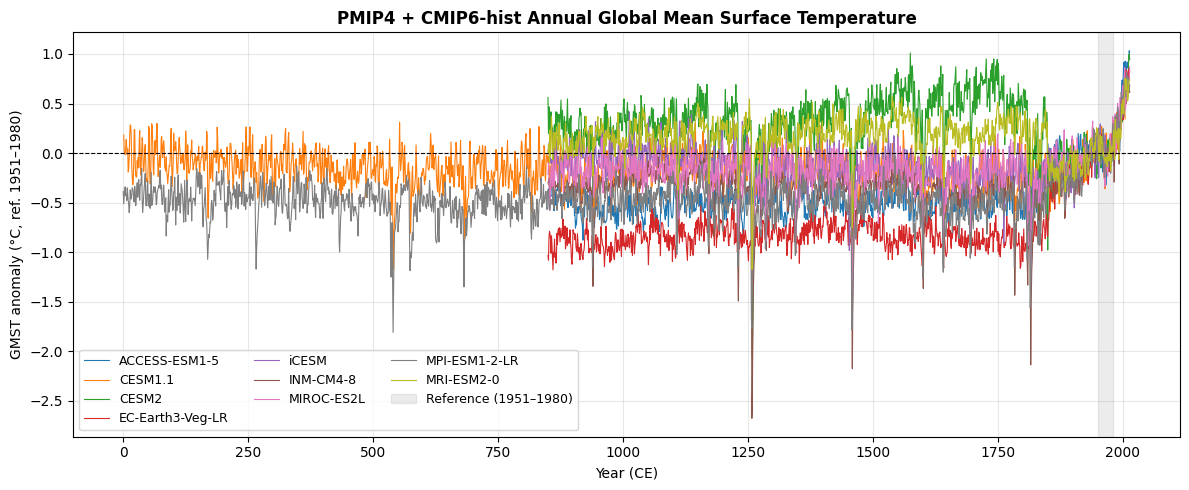

In [2]:
GMST_REF = (1951, 1980)

fig, ax = plt.subplots(figsize=(12, 5))
for name in models:
    s = gmst[name].dropna()
    ax.plot(s.index, s.values, label=name, linewidth=0.8)
ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
ax.axvspan(*GMST_REF, color='gray', alpha=0.15, label=f'Reference ({GMST_REF[0]}–{GMST_REF[1]})')
ax.set_xlabel('Year (CE)')
ax.set_ylabel(f'GMST anomaly (°C, ref. {GMST_REF[0]}–{GMST_REF[1]})')
ax.set_title('PMIP4 + CMIP6-hist Annual Global Mean Surface Temperature', fontweight='bold')
ax.legend(fontsize=9, loc='lower left', ncol = 3)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_spaghetti_raw.pdf', bbox_inches='tight',dpi=200)
plt.show()

## Full time series — one panel per model
Vertical dashed line marks the paleo/historical stitch point (1850).

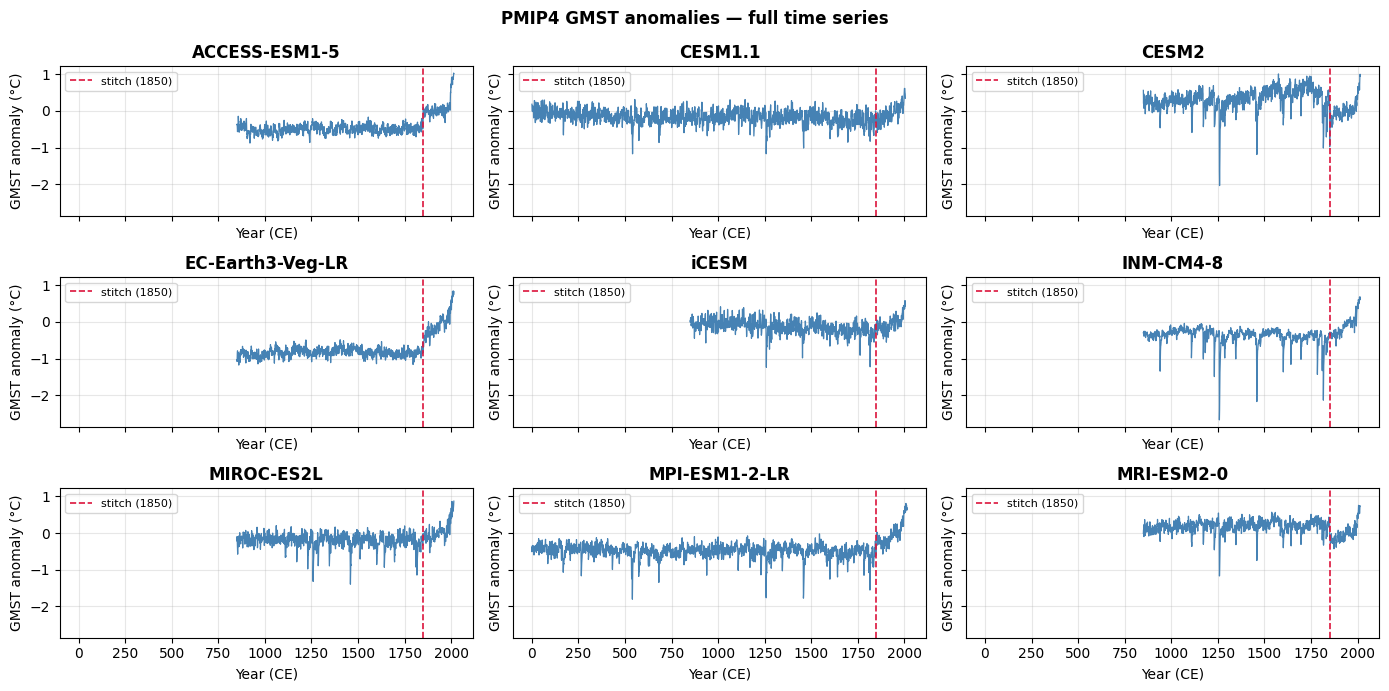

In [3]:
fig, axs = plt.subplots(3, 3, figsize=(14, 7), sharex=True, sharey=True)
axs = axs.ravel()

for ax, name in zip(axs, models):
    s = gmst[name].dropna()
    ax.plot(s.index, s.values, linewidth=0.9, color='steelblue')
    ax.axvline(1850, color='crimson', linewidth=1.2, linestyle='--', label='stitch (1850)')
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Year (CE)')
    ax.set_ylabel('GMST anomaly (°C)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle('PMIP4 GMST anomalies — full time series', fontweight='bold')
plt.tight_layout()
plt.show()

## Zoom around the stitch (1800–1900)
Paleo segment in blue, historical segment in orange; gap/jump at 1850 becomes visible.

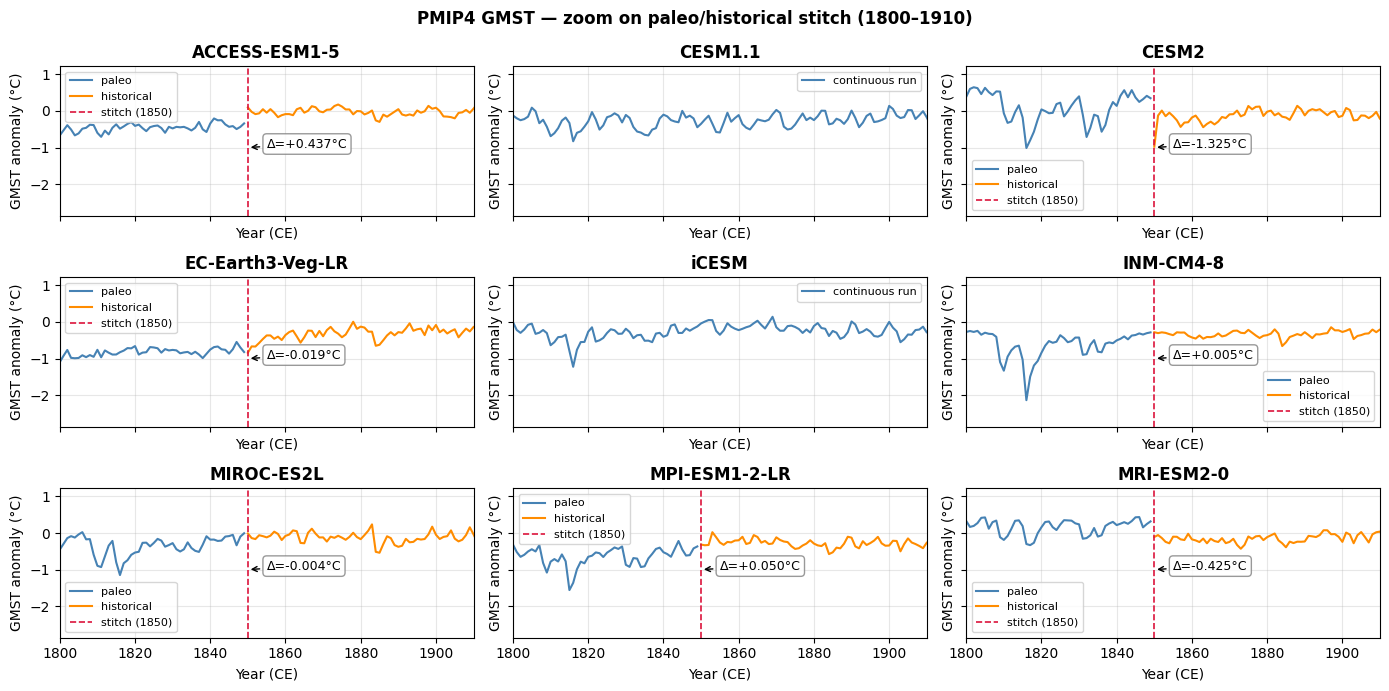

In [4]:
ZOOM = (1800, 1910)
STITCH = 1850

fig, axs = plt.subplots(3, 3, figsize=(14, 7), sharex=True, sharey=True)
axs = axs.ravel()

for ax, name in zip(axs, models):
    s = gmst[name].dropna()

    if has_stitch[name]:
        paleo = s[s.index < STITCH]
        hist  = s[s.index >= STITCH]
        ax.plot(paleo.index, paleo.values, color='steelblue',  linewidth=1.5, label='paleo')
        ax.plot(hist.index,  hist.values,  color='darkorange', linewidth=1.5, label='historical')
        ax.axvline(STITCH, color='crimson', linewidth=1.2, linestyle='--', label='stitch (1850)')
        if len(paleo) and len(hist):
            jump = hist.iloc[0] - paleo.iloc[-1]
            ax.annotate(f'Δ={jump:+.3f}°C',
                        xy=(STITCH, -1),
                        xytext=(STITCH + 5, -1),
                        fontsize=9, color='black',
                        arrowprops=dict(arrowstyle='->', color='black', lw=1),
                        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray'))
    else:
        ax.plot(s.index, s.values, color='steelblue', linewidth=1.5, label='continuous run')

    ax.set_xlim(ZOOM)
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Year (CE)')
    ax.set_ylabel('GMST anomaly (°C)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

for ax in axs[len(models):]:
    ax.set_visible(False)

plt.suptitle('PMIP4 GMST — zoom on paleo/historical stitch (1800–1910)', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_stich_corrections_zoom.pdf', bbox_inches='tight')
plt.show()

## Jump magnitude summary

In [5]:
print(f"{'Model':<22} {'last paleo (1849)':<22} {'first hist (1850)':<22} {'jump (°C)'}")
print('-' * 80)
for name in models:
    s = gmst[name].dropna()
    paleo = s[s.index < 1850]
    hist  = s[s.index >= 1850]
    if paleo.empty or hist.empty:
        print(f"{name:<22}  (incomplete — no stitch)")
        continue
    v_pre  = paleo.iloc[-1]
    v_post = hist.iloc[0]
    print(f"{name:<22} {v_pre:>10.3f}              {v_post:>10.3f}              {v_post - v_pre:>+.3f}")

Model                  last paleo (1849)      first hist (1850)      jump (°C)
--------------------------------------------------------------------------------
ACCESS-ESM1-5              -0.342                   0.096              +0.437
CESM1.1                    -0.446                  -0.352              +0.094
CESM2                       0.347                  -0.978              -1.325
EC-Earth3-Veg-LR           -0.822                  -0.841              -0.019
iCESM                      -0.123                  -0.039              +0.084
INM-CM4-8                  -0.285                  -0.280              +0.005
MIROC-ES2L                 -0.007                  -0.011              -0.004
MPI-ESM1-2-LR              -0.367                  -0.317              +0.050
MRI-ESM2-0                  0.317                  -0.108              -0.425


## Stitch correction: align past1000 to historical baseline

Three models (ACCESS-ESM1-5, EC-Earth3-Veg-LR, MRI-ESM2-0) show a significant jump at 1850 that can be corrected with a mean shift. Strategy: keep the historical run as-is; shift the past1000 segment so that its 1825–1849 mean equals the 1850–1874 mean of the historical run. We summarize the magnitude of the adjustment below. The idea is to apply this offset uniformly over the temperature field.

CESM2 shows a much larger, trend-like departure (see below) and requires a separate detrending step — it is handled in the next section.

In [6]:
MODELS_TO_CORRECT = ['ACCESS-ESM1-5', 'EC-Earth3-Veg-LR', 'MRI-ESM2-0']

# Compute offset = mean(hist 1850-1874) - mean(paleo 1825-1849) for each model
stitch_offsets = {}
print(f"{'Model':<22}  {'pre-mean (1825-1849)':<22}  {'post-mean (1850-1874)':<22}  {'offset (°C)'}")
print('-' * 85)
for name in MODELS_TO_CORRECT:
    s = gmst[name].dropna()
    pre_mean  = s[(s.index >= 1825) & (s.index < 1850)].mean()
    post_mean = s[(s.index >= 1850) & (s.index < 1875)].mean()
    stitch_offsets[name] = post_mean - pre_mean
    print(f"{name:<22}  {pre_mean:>10.4f}              {post_mean:>10.4f}              {stitch_offsets[name]:>+.4f}")

print()
print("Offsets to add to past1000 (pre-1850) segment:")
for name, offset in stitch_offsets.items():
    print(f"  {name}: {offset:+.4f} °C")

Model                   pre-mean (1825-1849)    post-mean (1850-1874)   offset (°C)
-------------------------------------------------------------------------------------
ACCESS-ESM1-5              -0.4206                 -0.0009              +0.4197
EC-Earth3-Veg-LR           -0.7821                 -0.4005              +0.3816
MRI-ESM2-0                  0.2025                 -0.1996              -0.4022

Offsets to add to past1000 (pre-1850) segment:
  ACCESS-ESM1-5: +0.4197 °C
  EC-Earth3-Veg-LR: +0.3816 °C
  MRI-ESM2-0: -0.4022 °C


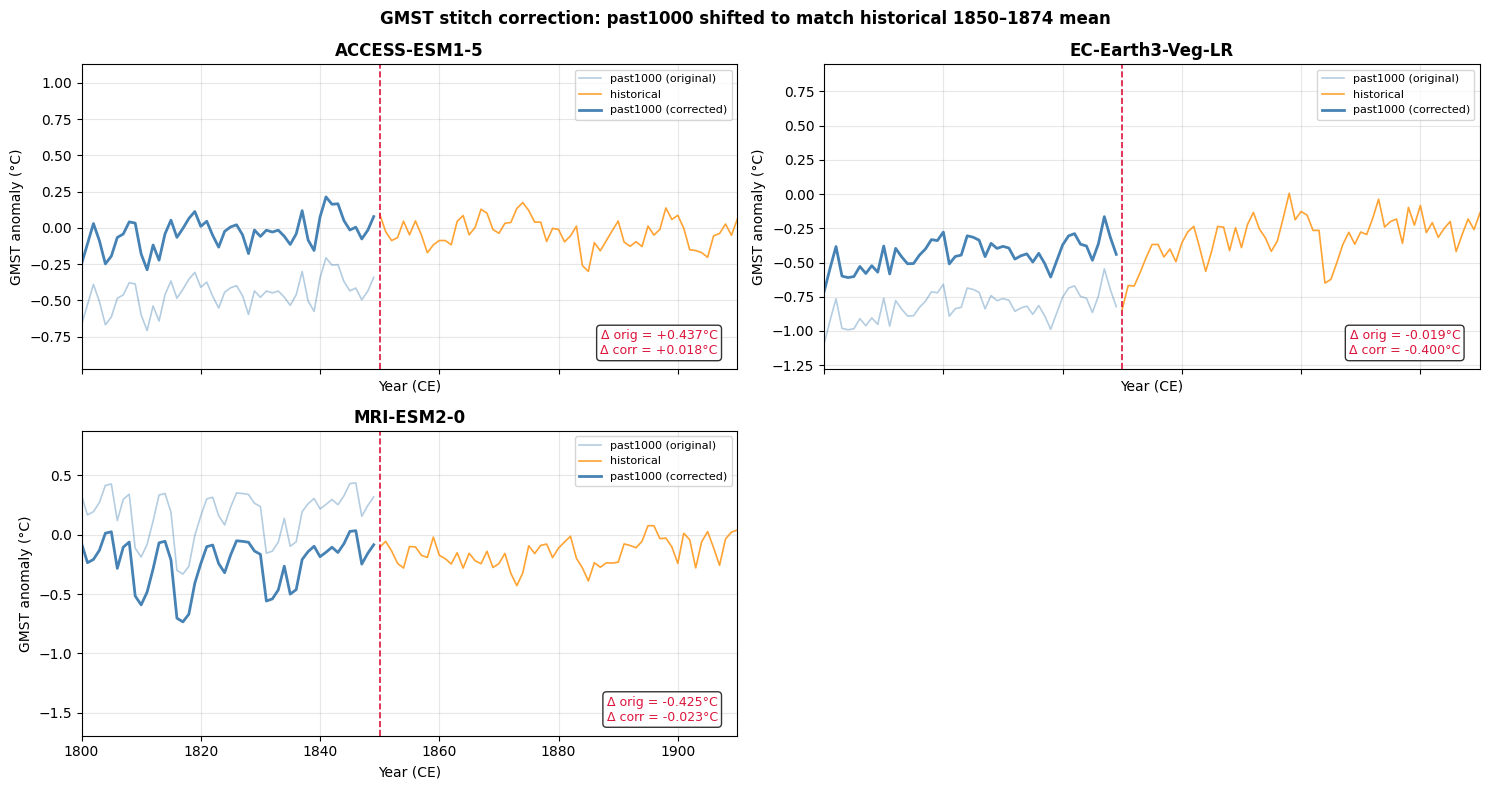

In [7]:
# Apply corrections: shift pre-1850 of each affected model
gmst_corrected = gmst.copy()
for name, offset in stitch_offsets.items():
    mask = gmst_corrected.index < 1850
    gmst_corrected.loc[mask, name] = gmst_corrected.loc[mask, name] + offset

# Plot original vs corrected for the affected models, zoomed around the stitch
ZOOM = (1800, 1910)

fig, axs = plt.subplots(2, 2, figsize=(15, 8), sharex=True, sharey=False)
axs = axs.ravel()

for ax, name in zip(axs, MODELS_TO_CORRECT):
    orig = gmst[name].dropna()
    corr = gmst_corrected[name].dropna()

    # original in muted style
    ax.plot(orig[orig.index < 1850].index,  orig[orig.index < 1850].values,
            color='steelblue', linewidth=1.2, alpha=0.4, label='past1000 (original)')
    ax.plot(orig[orig.index >= 1850].index, orig[orig.index >= 1850].values,
            color='darkorange', linewidth=1.2, alpha=0.8, label='historical')

    # corrected past1000 in solid blue
    ax.plot(corr[corr.index < 1850].index,  corr[corr.index < 1850].values,
            color='steelblue', linewidth=2.0, label='past1000 (corrected)')

    ax.axvline(1850, color='crimson', linewidth=1.2, linestyle='--')

    # annotate original and corrected jumps
    v_pre_orig  = orig[orig.index < 1850].iloc[-1]
    v_post      = orig[orig.index >= 1850].iloc[0]
    v_pre_corr  = corr[corr.index < 1850].iloc[-1]
    jump_orig   = v_post - v_pre_orig
    jump_corr   = v_post - v_pre_corr

    ax.text(0.97, 0.04, f'Δ orig = {jump_orig:+.3f}°C\nΔ corr = {jump_corr:+.3f}°C',
            transform=ax.transAxes, fontsize=9, ha='right', va='bottom',
            color='crimson', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    ax.set_xlim(ZOOM)
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Year (CE)')
    ax.set_ylabel('GMST anomaly (°C)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

for ax in axs[len(MODELS_TO_CORRECT):]:
    ax.set_visible(False)

plt.suptitle('GMST stitch correction: past1000 shifted to match historical 1850–1874 mean',
             fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_stich_corrections_zoom.pdf', bbox_inches='tight')
plt.show()

### Full-record view for all corrected models


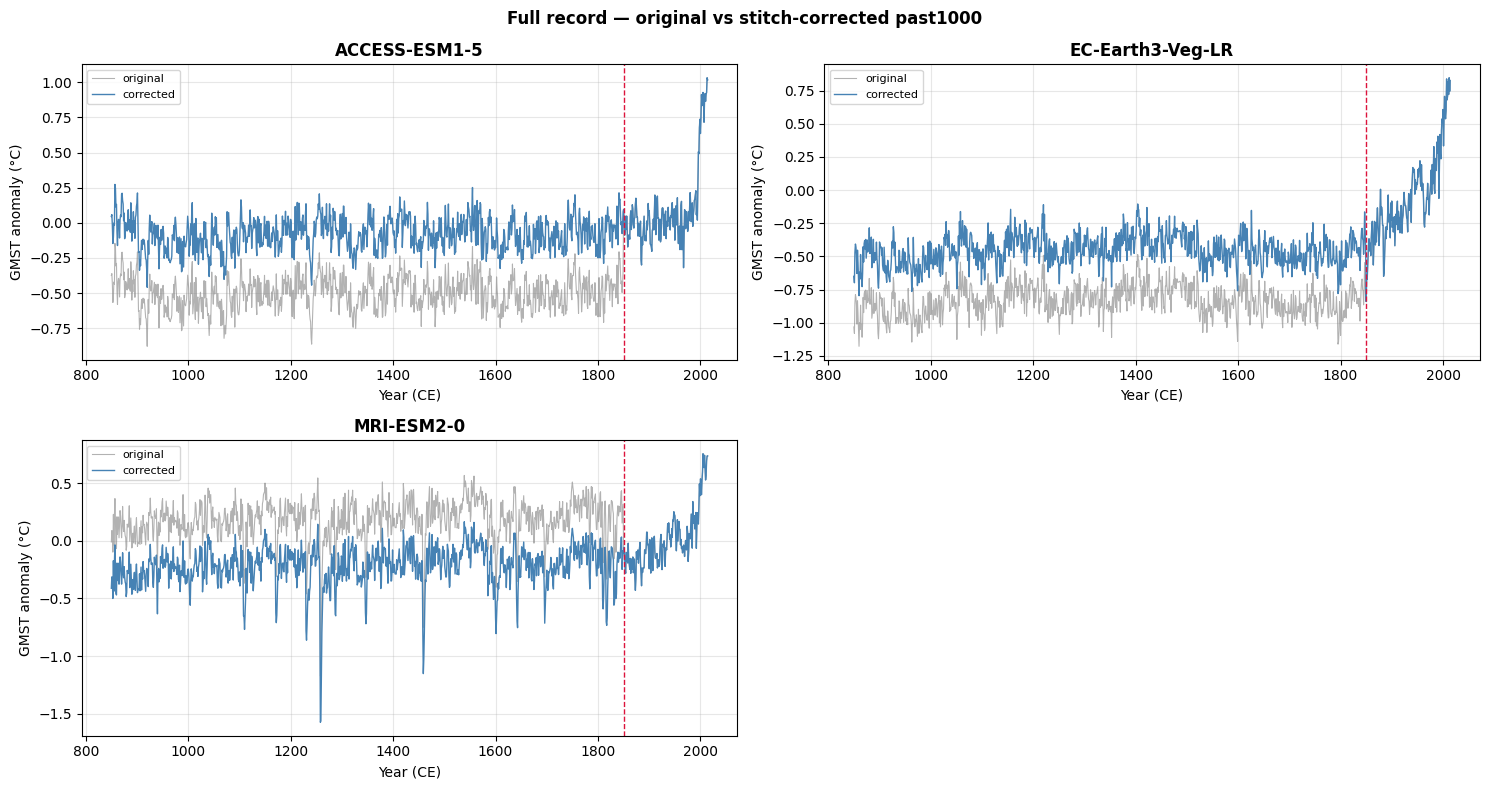

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(15, 8), sharex=False, sharey=False)
axs = axs.ravel()

for ax, name in zip(axs, MODELS_TO_CORRECT):
    orig = gmst[name].dropna()
    corr = gmst_corrected[name].dropna()

    ax.plot(orig.index, orig.values, color='grey',      linewidth=0.8, alpha=0.6, label='original')
    ax.plot(corr.index, corr.values, color='steelblue', linewidth=1.0,            label='corrected')
    ax.axvline(1850, color='crimson', linewidth=1.0, linestyle='--')
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Year (CE)')
    ax.set_ylabel('GMST anomaly (°C)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

for ax in axs[len(MODELS_TO_CORRECT):]:
    ax.set_visible(False)

plt.suptitle('Full record — original vs stitch-corrected past1000', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_stich_corrections_all_years.pdf', bbox_inches='tight')
plt.show()

## CESM2: linear detrend of the past1000 segment

**Context (Jiang Zhu, NCAR, pers. comm. 2026-07-01):** `past1000.002` was initialized from an 850 AD control simulation that included a "background" volcanic emission representing the average 850 AD forcing state. When the `past1000` run started, this background emission was immediately removed and replaced by transient PMIP4 volcanic forcing. The removal of the background forcing acts like a fictitious cooling that then slowly relaxes, producing an artificial **warming drift** throughout the ~1000-year segment — explaining the spurious "warm LIA" visible above.

The ideal correction is to subtract the drift estimated from the 850 AD control run, but that simulation may no longer be publicly available. Instead, we fit and remove a linear trend directly from the CESM2 `past1000` GMST, then remove the detrended segment's own 850–1849 mean. 

In [9]:
cesm2_orig  = gmst['CESM2'].dropna()
cesm2_paleo = cesm2_orig[cesm2_orig.index < 1850]
cesm2_hist  = cesm2_orig[cesm2_orig.index >= 1850]

# Fit and remove linear trend from the past1000 segment
yrs    = cesm2_paleo.index.values.astype(float)
coeffs = np.polyfit(yrs, cesm2_paleo.values, 1)
trend  = np.polyval(coeffs, yrs)

cesm2_detrended = pd.Series(
    cesm2_paleo.values - trend + cesm2_paleo.mean(),
    index=cesm2_paleo.index, name='CESM2'
)

# Align detrended past1000 by removing its own 850-1849 mean, rather than
# matching a noisy 50-yr tail window to the historical run's early mean
cesm2_offset = -cesm2_detrended.mean()
cesm2_corrected_paleo = cesm2_detrended + cesm2_offset

print(f"CESM2 past1000 linear trend:     {coeffs[0]*100:+.4f} °C / century")
print(f"  → total drift (~1000 yr):       {coeffs[0]*1000:+.3f} °C")
print(f"Stitch offset (post-detrend):    {cesm2_offset:+.4f} °C")

# Merge detrended past1000 with historical and update gmst_corrected
cesm2_final = pd.concat([cesm2_corrected_paleo, cesm2_hist])
gmst_corrected['CESM2'] = cesm2_final

CESM2 past1000 linear trend:     +0.0283 °C / century
  → total drift (~1000 yr):       +0.283 °C
Stitch offset (post-detrend):    -0.3255 °C


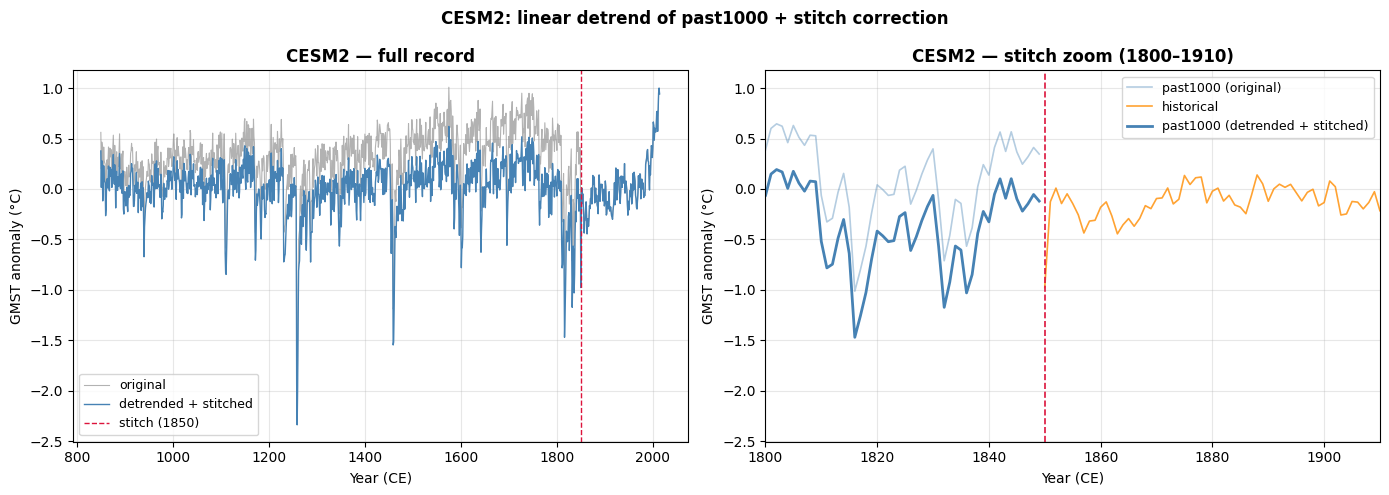

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Full record
cesm2_final = gmst_corrected['CESM2'].dropna()
axs[0].plot(cesm2_orig.index,  cesm2_orig.values,  color='grey',      linewidth=0.8, alpha=0.6, label='original')
axs[0].plot(cesm2_final.index, cesm2_final.values, color='steelblue', linewidth=1.0,            label='detrended + stitched')
axs[0].axvline(1850, color='crimson', linewidth=1.0, linestyle='--', label='stitch (1850)')
axs[0].set_title('CESM2 — full record', fontweight='bold')
axs[0].set_xlabel('Year (CE)')
axs[0].set_ylabel('GMST anomaly (°C)')
axs[0].grid(True, alpha=0.3)
axs[0].legend(fontsize=9)

# Zoom on stitch
axs[1].plot(cesm2_paleo.index,           cesm2_paleo.values,           color='steelblue', linewidth=1.2, alpha=0.4, label='past1000 (original)')
axs[1].plot(cesm2_hist.index,            cesm2_hist.values,            color='darkorange', linewidth=1.2, alpha=0.8, label='historical')
axs[1].plot(cesm2_corrected_paleo.index, cesm2_corrected_paleo.values, color='steelblue',  linewidth=2.0,            label='past1000 (detrended + stitched)')
axs[1].axvline(1850, color='crimson', linewidth=1.2, linestyle='--')
axs[1].set_xlim((1800, 1910))
axs[1].set_title('CESM2 — stitch zoom (1800–1910)', fontweight='bold')
axs[1].set_xlabel('Year (CE)')
axs[1].set_ylabel('GMST anomaly (°C)')
axs[1].grid(True, alpha=0.3)
axs[1].legend(fontsize=9)

plt.suptitle('CESM2: linear detrend of past1000 + stitch correction', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_CESM2_detrend.pdf', bbox_inches='tight')
plt.show()

## All-model overview — post-corrections
We now revisit the single-panel view after applying the `past1000` trend and offset corrections.

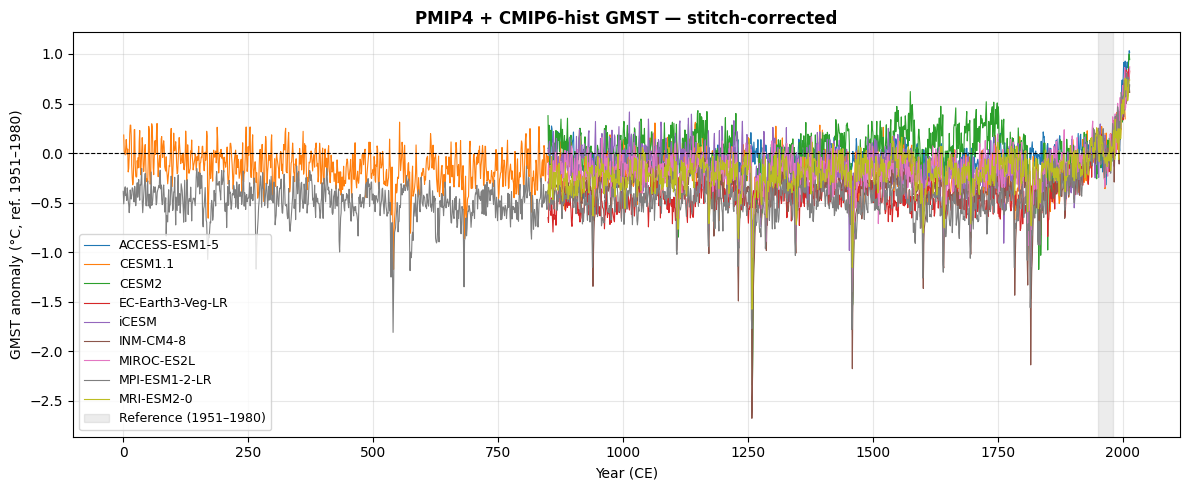

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
for name in models:
    s = gmst_corrected[name].dropna()
    ax.plot(s.index, s.values, label=name, linewidth=0.8)
ax.axhline(0, color='k', linewidth=0.8, linestyle='--')
ax.axvspan(*GMST_REF, color='gray', alpha=0.15, label=f'Reference ({GMST_REF[0]}–{GMST_REF[1]})')
ax.set_xlabel('Year (CE)')
ax.set_ylabel(f'GMST anomaly (°C, ref. {GMST_REF[0]}–{GMST_REF[1]})')
ax.set_title('PMIP4 + CMIP6-hist GMST — stitch-corrected', fontweight='bold')
ax.legend(fontsize=9, loc='lower left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_spaghetti_corrected.pdf', bbox_inches='tight')
plt.show()

Note: after removing the past1000 segment's own 850–1849 mean, CESM2 is closer to the pack but still runs slightly warmer than its closest analogs (CESM1.1, iCESM) over the paleo period. The boreholes will speak on this.

## Methodology check: stitch-correcting models that shouldn't need it

**Context.** After sharing the jump-magnitude results above, Johan Junglaus replied with a useful clarification about the `historical` runs we're stitching to:

> Maybe we did not make it clear enough in the CMIP6 past1000 protocol paper, but groups were requested to carry out one historical run with the end of past1000/past2k as initial condition (using the "restart" file from Dec. 1849). These experiments were marked by a different number in the "ensemble identifier" "i", i.e. in our case r1i2000p1f1. I have seen corresponding "r1f1i1000" experiments from the two Japanese past1000 runs in the CMIP6 archive (MRI-ESM2-0 and MIROC-ES2L).
> Did you take this into account?
> I assume that several groups did the past1000 experiment after they had already finished their "standard" historical run and then didn't bother or did not have resources to do another historical run with updated initial conditions.
>
> Maybe it would be a good idea to test the stitching methods looking at the differences you get comparing an experiment starting from the "correct" past1000/past2k restart and others starting from some PiControl experiment.

This came in response to the original question that kicked off this notebook:

> Hello Johann,
> I take the liberty to contact you with a question about the "1850 jump".
>
> I've long known that the PMIP past1000/past2k runs end in 1849, and that historical runs are not their continuation. However, for a project that my student Tanaya and I are working on, I'd like to bridge the gap in a sensible way (see attached document). Before I spam the PMIP list-serv, do you know of any solutions to this problem? I remember it coming up in PMIP3/CMIP5 so that is nothing new; I'm just unsure that a good solution exists. Thanks in advance for sharing what you know!
>
> Best,
> Julien

The implication: **MRI-ESM2-0 and MIROC-ES2L** are known to have a "correct" `r1i2000p1f1`-style historical continuation branched from the actual past1000/past2k Dec-1849 restart, so if we've paired them with the right ensemble member there should be little to no physical discontinuity at 1850 — any offset we detect is either noise or a sign that we grabbed the wrong (PiControl-branched) historical member. **MPI-ESM1-2-LR** is a related edge case: the underlying simulation ran continuously through `past2k`, but the archived paleo data is truncated at 1849, so a bookkeeping stitch is still required even though there's no restart discontinuity to correct for.

As a sanity check on our stitch-correction methodology (the same 1825–1849 vs. 1850–1874 mean-matching procedure used above), we apply it to these three models. A near-zero offset supports both (a) that the correction method doesn't manufacture spurious drift where none exists, and (b) that we're pairing the paleo run with the correct historical continuation. A large offset — as already seen for MRI-ESM2-0 above — is a flag that we may be stitching to the wrong (PiControl-initialized) historical ensemble member, exactly the failure mode our colleague suggested testing for.

In [12]:
MODELS_TO_CHECK = ['MPI-ESM1-2-LR', 'MRI-ESM2-0', 'MIROC-ES2L']

# Same offset formula as the main correction: mean(hist 1850-1874) - mean(paleo 1825-1849)
check_offsets = {}
print(f"{'Model':<22}  {'pre-mean (1825-1849)':<22}  {'post-mean (1850-1874)':<22}  {'offset (°C)'}")
print('-' * 85)
for name in MODELS_TO_CHECK:
    s = gmst[name].dropna()
    pre_mean  = s[(s.index >= 1825) & (s.index < 1850)].mean()
    post_mean = s[(s.index >= 1850) & (s.index < 1875)].mean()
    check_offsets[name] = post_mean - pre_mean
    print(f"{name:<22}  {pre_mean:>10.4f}              {post_mean:>10.4f}              {check_offsets[name]:>+.4f}")

Model                   pre-mean (1825-1849)    post-mean (1850-1874)   offset (°C)
-------------------------------------------------------------------------------------
MPI-ESM1-2-LR              -0.5673                 -0.2247              +0.3426
MRI-ESM2-0                  0.2025                 -0.1996              -0.4022
MIROC-ES2L                 -0.2620                 -0.0825              +0.1794


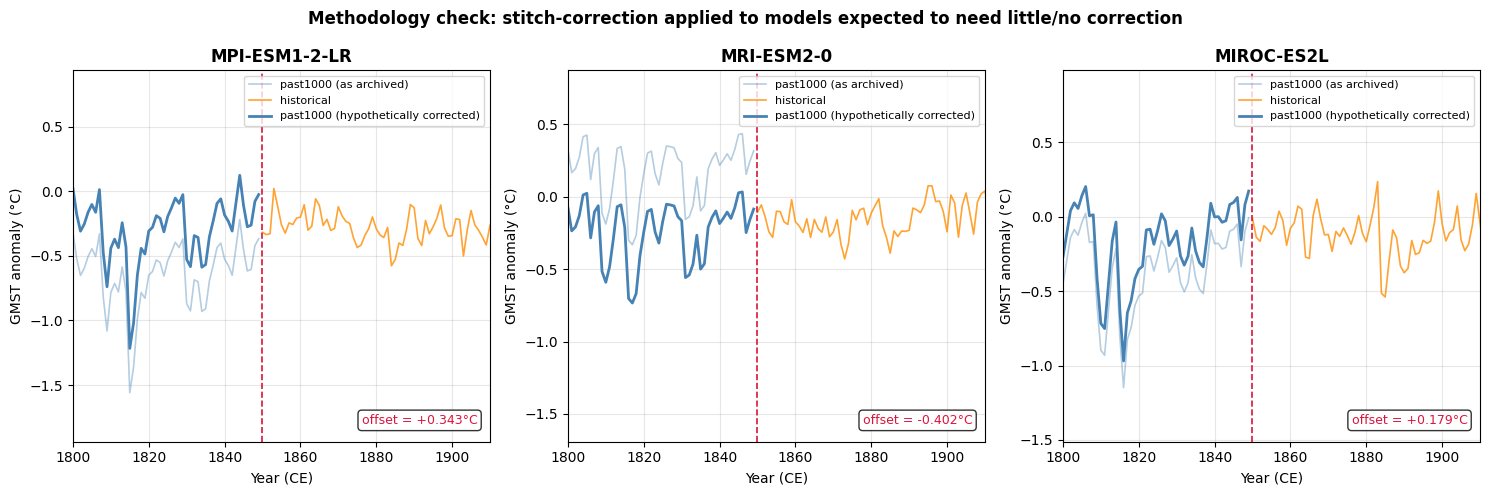

In [13]:
ZOOM_CHECK = (1800, 1910)

fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=False)

for ax, name in zip(axs, MODELS_TO_CHECK):
    s = gmst[name].dropna()
    paleo = s[s.index < 1850]
    hist  = s[s.index >= 1850]
    corrected_paleo = paleo + check_offsets[name]

    ax.plot(paleo.index, paleo.values, color='steelblue', linewidth=1.2, alpha=0.4, label='past1000 (as archived)')
    ax.plot(hist.index,  hist.values,  color='darkorange', linewidth=1.2, alpha=0.8, label='historical')
    ax.plot(corrected_paleo.index, corrected_paleo.values, color='steelblue', linewidth=2.0, label='past1000 (hypothetically corrected)')
    ax.axvline(1850, color='crimson', linewidth=1.2, linestyle='--')

    ax.text(0.97, 0.04, f'offset = {check_offsets[name]:+.3f}°C',
            transform=ax.transAxes, fontsize=9, ha='right', va='bottom',
            color='crimson', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    ax.set_xlim(ZOOM_CHECK)
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Year (CE)')
    ax.set_ylabel('GMST anomaly (°C)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle('Methodology check: stitch-correction applied to models expected to need little/no correction',
             fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_stitch_check.pdf', bbox_inches='tight')
plt.show()

**Reading the result.** None of the three offsets turn out to be negligible: MPI-ESM1-2-LR comes out around +0.34°C, MRI-ESM2-0 around −0.40°C, and MIROC-ES2L around +0.18°C — all in the same range as ACCESS-ESM1-5 and EC-Earth3-Veg-LR, the models we already treat as needing correction. That's not what a clean validation of the method would look like.

Two readings are possible, and they're not mutually exclusive:

1. **The colleague's hypothesis about ensemble members holds**, and our pipeline is pulling the *standard* `r1i1p1f1` historical run (branched from PiControl) for these models instead of the `r1i2000p1f1`-equivalent continuation from the true past1000/past2k restart. This would be worth checking directly against the CMIP6 ESGF holdings — exactly the comparison the colleague proposed (restart-branched historical vs. PiControl-branched historical).
2. **The 25-year window itself is picking up multidecadal internal variability**, not just a restart discontinuity. Even a physically continuous simulation can show a >0.1°C difference between two adjacent 25-year means simply from internal variability (e.g. volcanic recovery, decadal ocean modes) straddling 1850. If so, our mean-matching correction — applied uniformly to ACCESS-ESM1-5, EC-Earth3-Veg-LR, and MRI-ESM2-0 above — may be absorbing some of that natural variability into what we're calling a "stitch offset," which would mean those corrections are somewhat overconfident.

Either way, this check does **not** validate the method as cleanly as hoped, and is worth following up on: first by confirming which historical ensemble member (`r1i1p1f1` vs. `r1i2000p1f1`-equivalent) we're actually loading for MRI-ESM2-0 and MIROC-ES2L, and second by sanity-checking the window length against the models' internal variability (e.g. by testing several window widths and confirming the derived offsets are robust to that choice).

## Revised stitch: matching the 1849→1850 point, not the pre/post-1850 means

The methodology check above conflates two different things: the actual discontinuity introduced by switching from the `past1000`/`past2k` restart to a `historical` run, and ordinary multidecadal internal variability that happens to differ between the 25-year windows on either side of 1850. MPI-ESM1-2-LR and MIROC-ES2L are the clearest evidence of this — both connect with a genuinely small jump at the 1849/1850 boundary (see the "Jump magnitude summary" table above: +0.050°C and −0.004°C respectively), yet the mean-matching check assigned them offsets of +0.34°C and +0.18°C, because the 25-year windows used to estimate "pre" and "post" climate states aren't the same thing as the restart discontinuity itself.

Since what we're actually trying to correct is a jump introduced at a specific instant (the restart), the more defensible diagnostic is the single-year difference `v(1850) - v(1849)`, not a difference of decadal means. We revise the correction rule accordingly: compute the point offset for each stitched model, and only apply a correction when `|offset|` exceeds a chosen tolerance (below, 0.1°C — tight enough to catch a real restart artifact, loose enough to absorb a single year of internal-variability noise).

Note: MRI-ESM2-0's offset below should be treated as provisional. We've since located an `r1i1000p1f1`-style historical run for MRI-ESM2-0 — the continuation actually branched from the past1000/past2k Dec-1849 restart — and will re-run this diagnostic once it replaces the standard `r1i1p1f1` member currently in the pipeline.

In [14]:
TOLERANCE = 0.1  # °C; |offset| within this range is treated as noise, not a real stitch artifact

# All has_stitch models except CESM2, which needs the separate detrend treatment above
POINT_MODELS = ['ACCESS-ESM1-5', 'EC-Earth3-Veg-LR', 'INM-CM4-8', 'MIROC-ES2L', 'MPI-ESM1-2-LR', 'MRI-ESM2-0']

point_offsets = {}
print(f"{'Model':<22}  {'v(1849)':<10}  {'v(1850)':<10}  {'offset (°C)':<12}  {'needs correction?'}")
print('-' * 80)
for name in POINT_MODELS:
    s = gmst[name].dropna()
    v_1849 = s.loc[1849]
    v_1850 = s.loc[1850]
    offset = v_1850 - v_1849
    point_offsets[name] = offset
    flag = 'yes' if abs(offset) > TOLERANCE else 'no'
    print(f"{name:<22}  {v_1849:>8.3f}    {v_1850:>8.3f}    {offset:>+.3f}         {flag}")

MODELS_TO_CORRECT_POINT = [name for name, off in point_offsets.items() if abs(off) > TOLERANCE]
print(f"\nModels requiring a point-based correction (|offset| > {TOLERANCE}°C): {MODELS_TO_CORRECT_POINT}")

Model                   v(1849)     v(1850)     offset (°C)   needs correction?
--------------------------------------------------------------------------------
ACCESS-ESM1-5             -0.342       0.096    +0.437         yes
EC-Earth3-Veg-LR          -0.822      -0.841    -0.019         no
INM-CM4-8                 -0.285      -0.280    +0.005         no
MIROC-ES2L                -0.007      -0.011    -0.004         no
MPI-ESM1-2-LR             -0.367      -0.317    +0.050         no
MRI-ESM2-0                 0.317      -0.108    -0.425         yes

Models requiring a point-based correction (|offset| > 0.1°C): ['ACCESS-ESM1-5', 'MRI-ESM2-0']


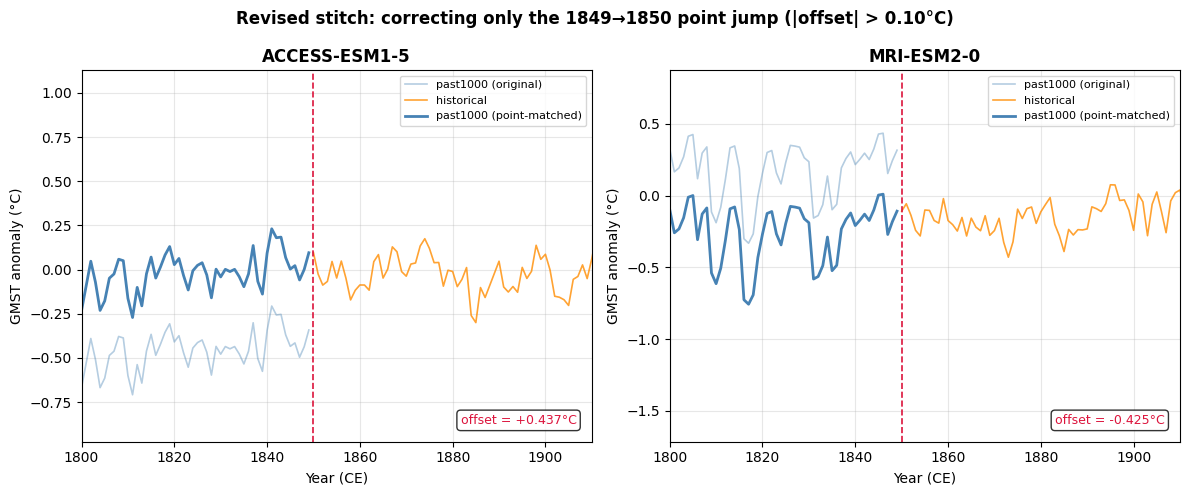

In [15]:
# Build a revised corrected dataframe: start from the raw data, reuse the CESM2
# detrend treatment from above (independent of the mean-vs-point question), then
# apply the point-matched offset only to models whose 1849->1850 jump exceeds TOLERANCE.
gmst_corrected_pointmatch = gmst.copy()
gmst_corrected_pointmatch['CESM2'] = gmst_corrected['CESM2']

for name in MODELS_TO_CORRECT_POINT:
    mask = gmst_corrected_pointmatch.index < 1850
    gmst_corrected_pointmatch.loc[mask, name] = gmst_corrected_pointmatch.loc[mask, name] + point_offsets[name]

fig, axs = plt.subplots(1, len(MODELS_TO_CORRECT_POINT), figsize=(6 * len(MODELS_TO_CORRECT_POINT), 5), sharey=False)
if len(MODELS_TO_CORRECT_POINT) == 1:
    axs = [axs]

for ax, name in zip(axs, MODELS_TO_CORRECT_POINT):
    orig = gmst[name].dropna()
    corr = gmst_corrected_pointmatch[name].dropna()

    ax.plot(orig[orig.index < 1850].index, orig[orig.index < 1850].values,
            color='steelblue', linewidth=1.2, alpha=0.4, label='past1000 (original)')
    ax.plot(orig[orig.index >= 1850].index, orig[orig.index >= 1850].values,
            color='darkorange', linewidth=1.2, alpha=0.8, label='historical')
    ax.plot(corr[corr.index < 1850].index, corr[corr.index < 1850].values,
            color='steelblue', linewidth=2.0, label='past1000 (point-matched)')
    ax.axvline(1850, color='crimson', linewidth=1.2, linestyle='--')

    ax.text(0.97, 0.04, f'offset = {point_offsets[name]:+.3f}°C',
            transform=ax.transAxes, fontsize=9, ha='right', va='bottom',
            color='crimson', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    ax.set_xlim((1800, 1910))
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Year (CE)')
    ax.set_ylabel('GMST anomaly (°C)')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(f'Revised stitch: correcting only the 1849→1850 point jump (|offset| > {TOLERANCE:.2f}°C)',
             fontweight='bold')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_pointmatch_correction.pdf', bbox_inches='tight')
plt.show()

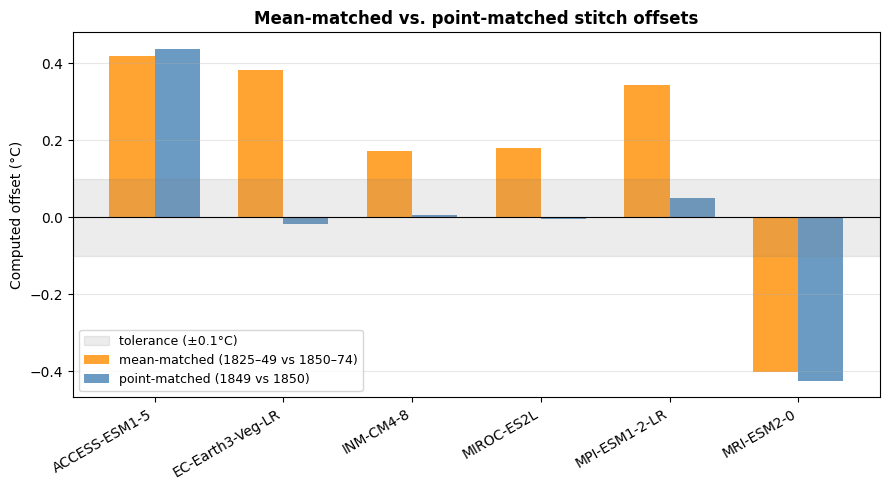

In [16]:
# Compare the two correction rules side by side across all 6 stitched, non-CESM2 models
mean_based = {}
for name in POINT_MODELS:
    s = gmst[name].dropna()
    pre_mean  = s[(s.index >= 1825) & (s.index < 1850)].mean()
    post_mean = s[(s.index >= 1850) & (s.index < 1875)].mean()
    mean_based[name] = post_mean - pre_mean

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(POINT_MODELS))
width = 0.35
ax.bar(x - width/2, [mean_based[n] for n in POINT_MODELS], width,
       label='mean-matched (1825–49 vs 1850–74)', color='darkorange', alpha=0.8)
ax.bar(x + width/2, [point_offsets[n] for n in POINT_MODELS], width,
       label='point-matched (1849 vs 1850)', color='steelblue', alpha=0.8)
ax.axhline(0, color='k', linewidth=0.8)
ax.axhspan(-TOLERANCE, TOLERANCE, color='gray', alpha=0.15, label=f'tolerance (±{TOLERANCE}°C)')
ax.set_xticks(x)
ax.set_xticklabels(POINT_MODELS, rotation=30, ha='right')
ax.set_ylabel('Computed offset (°C)')
ax.set_title('Mean-matched vs. point-matched stitch offsets', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f'{FIGURE_FOLDER}PMIP4_GMST_offset_comparison.pdf', bbox_inches='tight')
plt.show()

**Result.** Under the point-matched criterion (tolerance = ±0.1°C), only **ACCESS-ESM1-5** (+0.437°C) and **MRI-ESM2-0** (−0.425°C) still require a correction. EC-Earth3-Veg-LR (−0.019°C), INM-CM4-8 (+0.005°C), MIROC-ES2L (−0.004°C), and MPI-ESM1-2-LR (+0.050°C) all fall within tolerance — consistent with Johann Junglaus's account that these historical runs are properly initialized from the past1000/past2k restart, and with MPI-ESM1-2-LR's paleo/historical split being a pure archiving artifact rather than a restart discontinuity.

This is a real change from the mean-matching approach above, which flagged EC-Earth3-Veg-LR (+0.38°C) as needing correction and would have shifted its entire paleo segment by nearly 0.4°C to absorb what now looks like multidecadal internal variability rather than a restart artifact.

MRI-ESM2-0's correction here should still be treated as provisional pending the incorporation of the newly located `r1i1000p1f1` historical run — we expect its point-based offset to shrink toward zero once that replaces the standard `r1i1p1f1` member currently in the pipeline, similar to what we now see for MIROC-ES2L.

**Going forward, we recommend the point-matched, tolerance-gated offset (`gmst_corrected_pointmatch`) as the default stitch-correction rule.** The mean-matching section above is retained for comparison but should not be used for production corrections — it conflates the restart discontinuity with ordinary internal variability on either side of 1850.